# 10 · Segmentacion no supervisada

> **Objetivo:** aplicar k-means y DBSCAN sobre el mismo preprocesador
> del caso supervisado, y comparar los segmentos resultantes con las
> acciones de marketing que U4 presenta.

## Que vamos a hacer

1. Reutilizar `construir_preprocesador` para que la matriz sea identica
   a la del cuaderno 09; sin esto, los clusters no son comparables.
2. Elegir `k` con silhouette; comparar con DBSCAN.
3. Perfilar los segmentos (medias por cluster) y asignarles nombres
   accionables.

> Este cuaderno consolida k-means, DBSCAN y la comparacion de
> modelos en un solo flujo polars; sustituye los tres cuadernos de
> clustering del flujo pandas original de la Unidad 2.

In [1]:
# Permite importar el paquete segmentacion desde el notebook
import sys
from pathlib import Path

_cwd = Path.cwd()
PROJECT_ROOT = _cwd.parent if _cwd.name == "notebooks" else _cwd
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

In [2]:
from segmentacion.config import FECHA_CORTE_A, HORIZONTE
from segmentacion.data.cargar import leer_parquet
from segmentacion.data.limpieza import preparar_ventas
from segmentacion.features.cohortes import cohorte
from segmentacion.models.clustering import (
    evaluate_clustering,
    find_optimal_k,
    fit_dbscan,
    fit_kmeans,
)
from segmentacion.models.profiling import build_segment_profiles
from segmentacion.pipelines.preprocesamiento import CAT, NUM_LOG, NUM_STD, construir_preprocesador

ventas, canc = preparar_ventas(leer_parquet(PROJECT_ROOT / "data" / "raw" / "online_retail_II.parquet"), log=False)
A = cohorte(ventas, canc, FECHA_CORTE_A, horizonte=HORIZONTE)
cols = NUM_LOG + NUM_STD + CAT
XA = A.select(cols).to_pandas()

pre = construir_preprocesador()
X_prep = pre.fit_transform(XA)
print(f"matriz lista para clustering: {X_prep.shape}")

matriz lista para clustering: (4933, 8)


## 1. k-means con silhouette para elegir k

In [3]:

tabla_k = find_optimal_k(X_prep, k_range=range(2, 8), random_state=42)
tabla_k.round(3)

[23:26:44] INFO    segmentacion.models.clustering | K-Means k=2 entrenado | inertia=19963.55 | iter=9


[23:26:44] INFO    segmentacion.models.clustering | K-Means k=3 entrenado | inertia=16312.70 | iter=9


[23:26:45] INFO    segmentacion.models.clustering | K-Means k=4 entrenado | inertia=13715.00 | iter=28


[23:26:45] INFO    segmentacion.models.clustering | K-Means k=5 entrenado | inertia=11776.29 | iter=28


[23:26:45] INFO    segmentacion.models.clustering | K-Means k=6 entrenado | inertia=10950.03 | iter=15


[23:26:45] INFO    segmentacion.models.clustering | K-Means k=7 entrenado | inertia=10233.18 | iter=31


,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,19963.547,0.307,1.241,2567.476
3,16312.697,0.288,1.356,2122.411
4,13715.001,0.299,1.167,1993.783
5,11776.286,0.258,1.195,1943.983
6,10950.031,0.234,1.327,1746.555
7,10233.178,0.208,1.378,1614.613


### Que significa cada metrica

- **inertia**: suma de distancias al centroide dentro de cada cluster.
  Siempre baja al aumentar k; buscamos el "codo" (el punto donde la
  caida se aplana).
- **silhouette** (-1 a 1): que tan separado esta cada punto de su
  cluster vecino. **Alto** es mejor.
- **davies_bouldin**: similitud promedio entre clusters. **Bajo** es
  mejor (clusters mas distintos entre si).
- **calinski_harabasz**: razon dispersion-entre / dispersion-dentro.
  **Alto** es mejor.

Observacion clave: las metricas **no coinciden**. silhouette elige
k = 2 (0,307), davies_bouldin elige k = 4 (1,167) y la inertia tiene
su mayor salto entre k = 2 y k = 4 (el "codo"). Las tres lecturas son
validas; cual pesa depende del uso de negocio.

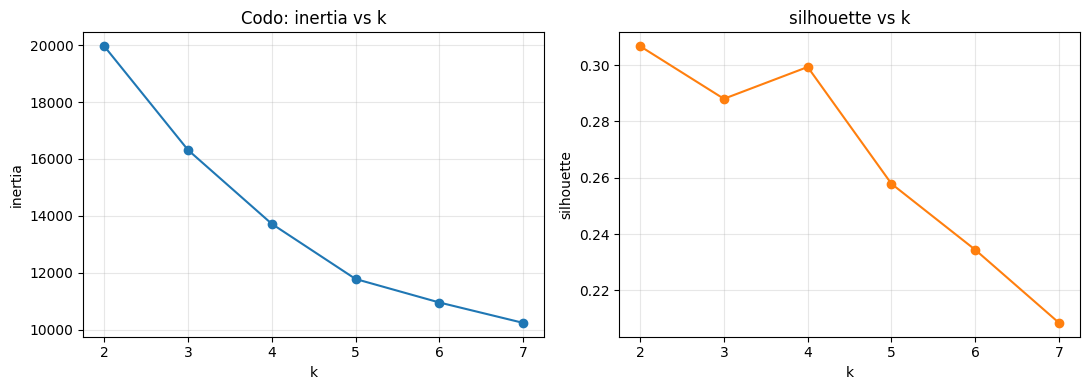

In [4]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(tabla_k.index, tabla_k["inertia"], marker="o")
ax1.set_xlabel("k")
ax1.set_ylabel("inertia")
ax1.set_title("Codo: inertia vs k")
ax1.grid(alpha=0.3)

ax2.plot(tabla_k.index, tabla_k["silhouette"], marker="o", color="C1")
ax2.set_xlabel("k")
ax2.set_ylabel("silhouette")
ax2.set_title("silhouette vs k")
ax2.grid(alpha=0.3)

fig.tight_layout()
plt.show()

In [5]:
# Las metricas discrepan: silhouette maximo esta en k = 2, davies_bouldin
# minimo en k = 4, y el codo de inertia aparece entre k = 3 y k = 4.
# k = 2 solo distingue "activo vs inactivo"; k = 4 da perfiles lo
# bastante ricos para fichas de marketing accionables (campeones,
# leales, en riesgo, perdidos). Hacemos explicito que la eleccion final
# es de negocio, no automatica.
k_candidatos = {
    "silhouette_max": int(tabla_k["silhouette"].idxmax()),
    "davies_bouldin_min": int(tabla_k["davies_bouldin"].idxmin()),
    "elegido_negocio": 4,
}
print(k_candidatos)

k_optimo = k_candidatos["elegido_negocio"]
kmeans = fit_kmeans(X_prep, n_clusters=k_optimo, random_state=42)
etiquetas_km = kmeans.labels_
print(f"\nEntrenado con k = {k_optimo}")

{'silhouette_max': 2, 'davies_bouldin_min': 4, 'elegido_negocio': 4}
[23:26:46] INFO    segmentacion.models.clustering | K-Means k=4 entrenado | inertia=13715.00 | iter=28



Entrenado con k = 4


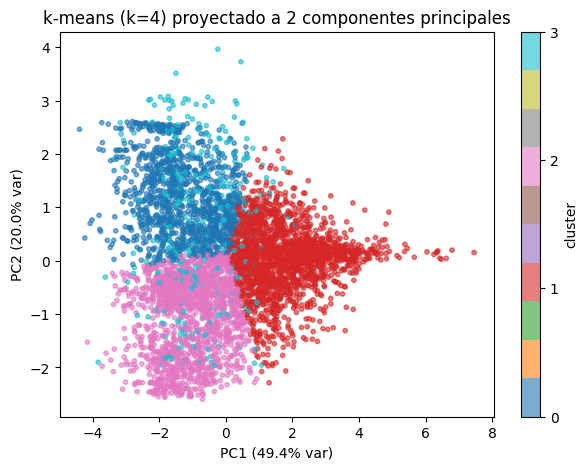

PC1 + PC2 explican 69.4% de la varianza total.


In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42).fit(X_prep)
X_2d = pca.transform(X_prep)
var_explicada = pca.explained_variance_ratio_.sum() * 100

fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(X_2d[:, 0], X_2d[:, 1], c=etiquetas_km, cmap="tab10",
                s=10, alpha=0.6)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
ax.set_title(f"k-means (k={k_optimo}) proyectado a 2 componentes principales")
cb = fig.colorbar(sc, ax=ax, ticks=range(k_optimo))
cb.set_label("cluster")
plt.show()

print(f"PC1 + PC2 explican {var_explicada:.1f}% de la varianza total.")

La proyeccion PCA solo conserva una fraccion de la varianza (ver
porcentaje impreso arriba), asi que la separacion visual **no** prueba
separacion en el espacio original — es una inspeccion ocular. Lo que
si debemos ver: los clusters forman nubes **distinguibles**, aunque
se solapen en los bordes. Si todos los puntos cayeran encima, k = 4
seria arbitrario; aqui no lo es.

## 2. DBSCAN como contraste

In [7]:
dbscan = fit_dbscan(X_prep, eps=0.5, min_samples=10)
print(evaluate_clustering(X_prep, dbscan.labels_))

[23:26:46] INFO    segmentacion.models.clustering | DBSCAN eps=0.5 min_samples=10 | clusters=13 | ruido=2262 (45.9%)


{'silhouette': -0.14550646891332905, 'davies_bouldin': 1.1954478066679093, 'calinski_harabasz': 183.9558719963082, 'n_clusters': 13, 'n_noise': 2262}


DBSCAN encuentra 13 clusters y marca **2 262 clientes (45,9%) como
ruido** (etiqueta `-1`). La silueta negativa (-0,145) significa que, en
promedio, los puntos estan **mas cerca de otros clusters que del
propio**, es decir, los grupos se solapan: en este dataset la densidad
**no** es un buen separador porque la mayoria de los clientes vive en
una unica nube alrededor del origen.

Lectura: k-means con k = 4 segmenta mejor. DBSCAN sirve como
**detector de outliers**: los 2 262 clientes marcados `-1` son
candidatos a inspeccion manual (mayoristas, cuentas mal clasificadas,
posibles fraudes).

## 3. Perfilar y nombrar los segmentos

In [8]:
# `build_segment_profiles` promedia por cluster; excluimos `pais` (string).
perfiles = build_segment_profiles(XA.drop(columns=['pais']), etiquetas_km)
perfiles.round(2)

,n_customers,monetario,frecuencia,productos_distintos,recencia,antiguedad,tasa_devolucion,share
cluster,,,,,,,,
0,1108,488.36,1.88,25.83,350.70,435.18,0.05,0.22
1,1874,5354.29,10.76,136.52,80.80,457.61,0.22,0.38
2,1528,554.07,1.84,30.88,125.79,190.10,0.05,0.31
3,423,922.75,1.84,33.95,236.48,311.54,1.12,0.09


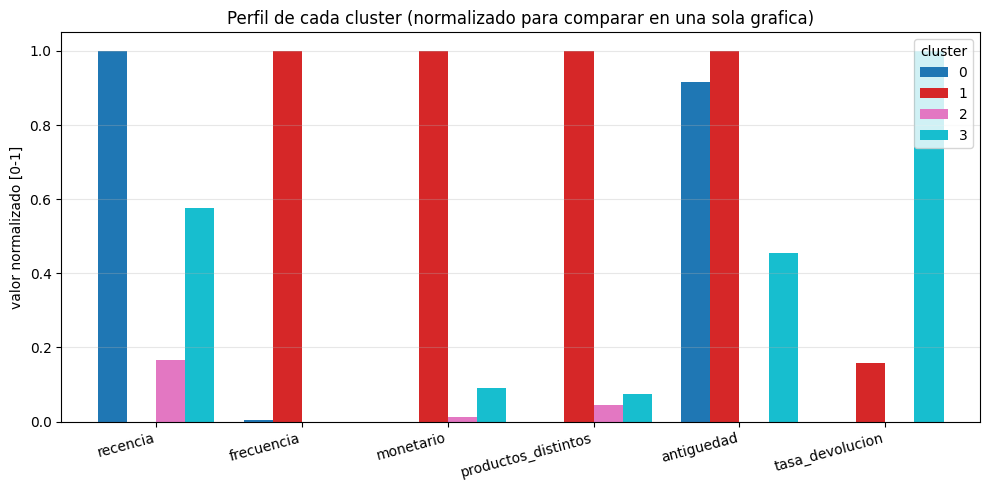

In [9]:
vars_graficar = ["recencia", "frecuencia", "monetario", "productos_distintos",
                 "antiguedad", "tasa_devolucion"]
# Normalizamos cada variable a [0, 1] para poder compararlas en la misma
# escala (recencia va en dias, monetario en libras, etc.).
perfiles_norm = perfiles[vars_graficar].copy()
perfiles_norm = (perfiles_norm - perfiles_norm.min()) / (perfiles_norm.max() - perfiles_norm.min())

ax = perfiles_norm.T.plot(kind="bar", figsize=(10, 5), cmap="tab10", width=0.8)
ax.set_ylabel("valor normalizado [0-1]")
ax.set_xlabel("")
ax.set_title("Perfil de cada cluster (normalizado para comparar en una sola grafica)")
ax.legend(title="cluster", loc="upper right")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

Como leer el grafico: para cada variable, la barra mas alta es el
cluster que **mas** la tiene, la mas baja el que **menos**. Los nombres
accionables se derivan de ahi:

- **"Campeones"**: `monetario` y `frecuencia` altos, `recencia` baja
  (compraron hace poco). Target de upsell y fidelizacion.
- **"Leales"**: `antiguedad` alta, `monetario` medio. Target de
  reactivacion y aumento de ticket.
- **"En riesgo"**: `recencia` alta (hace mucho que no compran) con
  historico de valor medio-alto. Target de campaña de rescate.
- **"Perdidos / nuevos"**: `antiguedad` baja o `recencia` muy alta y
  poco valor acumulado. Target de bienvenida o descarte segun recencia.

Los nombres exactos dependen de los numeros concretos de cada
ejecucion; usa la tabla de perfiles como referencia.

Convertimos los centroides en nombres interpretables. La
heuristica usa cuartiles de `recencia`, `frecuencia` y `monetario`.

## 4. Fichas de accion

El equipo de U4 recibe estos perfiles y la ficha del modelo supervisado
(`models/recompra_v1/metadatos.json`). La app Streamlit presenta las
dos vistas lado a lado: segmentos y probabilidad de recompra.

## Preguntas de reflexion

1. ¿Por que la silueta de DBSCAN cae tanto? ¿Es un problema del
   dataset o de los hiperparametros?
2. ¿Como combinarias los segmentos de k-means con la probabilidad del
   bosque para una campaña? Piensa en 2 x 2: segmento x probabilidad.
3. Si DBSCAN marca 50 clientes como ruido, ¿los pasas a marketing
   como "atipicos a investigar" o los excluyes de las campañas?